<a href="https://colab.research.google.com/github/ReversePI78/-DevelRocket-AI-game-review-analysis/blob/main/8%EC%B0%A8%EC%8B%9C_%EB%82%B4%EA%B2%8C%EC%9E%84%EB%A6%AC%EB%B7%B0%EC%88%98%EC%A7%91%ED%95%98%EA%B8%B0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 8차시: 내 게임 리뷰 수집하기

**학습 목표**
- 관심 있는 게임을 직접 선택하기
- steamreviews로 실제 리뷰 데이터 수집하기
- 수집한 데이터를 CSV로 저장하기

---

## 1. steamreviews 설치

먼저 Steam 리뷰 수집 라이브러리를 설치합니다.

In [1]:
# steamreviews 라이브러리 설치
!pip install steamreviews -q
print("설치 완료!")

설치 완료!


## 2. 내가 분석할 게임 선택하기

### 게임 ID 찾는 방법
1. [Steam 스토어](https://store.steampowered.com/)에서 원하는 게임 검색
2. 게임 페이지 URL에서 숫자 확인
   - 예: `https://store.steampowered.com/app/413150/Stardew_Valley/`
   - 게임 ID = **413150**

### 추천 게임 (한국어 리뷰 많음)
| 게임 | ID | 특징 |
|------|-----|------|
| Stardew Valley | 413150 | 힐링 게임, 긍정 리뷰 많음 |
| PUBG | 578080 | FPS, 다양한 의견 |
| Lost Ark | 1599340 | MMORPG, 장문 리뷰 |
| Terraria | 105600 | 샌드박스, 호평 위주 |
| Counter-Strike 2 | 730 | FPS, 리뷰 매우 많음 |

In [2]:
# ============================================
# 여기에 분석하고 싶은 게임 ID를 입력하세요!
# ============================================

MY_GAME_ID = '413150'  # <-- 이 숫자를 바꾸세요!
MY_GAME_NAME = 'Stardew Valley'  # <-- 게임 이름도 바꾸세요!

print(f"선택한 게임: {MY_GAME_NAME}")
print(f"게임 ID: {MY_GAME_ID}")

선택한 게임: Stardew Valley
게임 ID: 413150


## 3. 리뷰 수집하기

steamreviews 라이브러리로 한국어 리뷰를 수집합니다.

In [3]:
import steamreviews

# 리뷰 수집 (한국어만)
print(f"{MY_GAME_NAME} 리뷰 수집 중...")
print("(게임에 따라 1-5분 정도 걸릴 수 있습니다)")
print()

review_dict, query_count = steamreviews.download_reviews_for_app_id(
    MY_GAME_ID,
    chosen_request_params={'language': 'korean'}
)

print(f"수집 완료!")
print(f"- 수집된 리뷰 수: {len(review_dict['reviews'])}개")
print(f"- API 요청 횟수: {query_count}회")

Stardew Valley 리뷰 수집 중...
(게임에 따라 1-5분 정도 걸릴 수 있습니다)

[appID = 413150] expected #reviews = 36219
Number of queries 150 reached. Cooldown: 310 seconds
Number of queries 150 reached. Cooldown: 310 seconds
수집 완료!
- 수집된 리뷰 수: 36214개
- API 요청 횟수: 64회


## 4. 데이터 구조 확인하기

수집한 데이터가 어떻게 생겼는지 살펴봅시다.

In [14]:
# 리뷰 하나만 꺼내서 구조 확인 (작성자 개인정보는 가리고 출력)
sample_id = list(review_dict['reviews'].keys())[0]
sample_review = review_dict['reviews'][sample_id]
author_keys = ['num_reviews', 'playtime_forever', 'playtime_last_two_weeks', 'playtime_at_review']
print("리뷰 데이터 구조:")
print("="*50)
print("author 포함 키:", list(sample_review['author'].keys()))
print("author (플레이 정보만 표시):", {k: sample_review['author'][k] for k in author_keys if k in sample_review['author']})
print("\n".join(f"{k}: {str(v)[:100]}" for k, v in sample_review.items() if k != 'author'))

리뷰 데이터 구조:
author 포함 키: ['steamid', 'num_games_owned', 'num_reviews', 'playtime_forever', 'playtime_last_two_weeks', 'playtime_at_review', 'last_played', 'personaname', 'persona_status', 'profile_url', 'avatar']
author (플레이 정보만 표시): {'num_reviews': 1, 'playtime_forever': 4173, 'playtime_last_two_weeks': 95, 'playtime_at_review': 4077}
recommendationid: 240772757
language: koreana
review: 레전드 힐링 게임
timestamp_created: 1795341986
timestamp_updated: 1795341986
voted_up: True
votes_up: 0
votes_funny: 0
weighted_vote_score: 0.5
comment_count: 0
steam_purchase: True
received_for_free: False
written_during_early_access: False
primarily_steam_deck: False
refunded: False
location: 
reactions: []


## 5. DataFrame으로 변환하기

딕셔너리 형태를 분석하기 좋은 DataFrame으로 바꿉니다.

In [6]:
import pandas as pd
from datetime import datetime

# 리뷰 데이터를 리스트로 변환
reviews_list = []

for review_id, data in review_dict['reviews'].items():
    reviews_list.append({
        'review_id': review_id,
        'review_text': data['review'],
        'recommended': data['voted_up'],  # True=추천, False=비추천
        'playtime_hours': round(data['author']['playtime_forever'] / 60, 1),
        'helpful_votes': data['votes_up'],
        'funny_votes': data['votes_funny'],
        'posted_date': datetime.fromtimestamp(data['timestamp_created']).strftime('%Y-%m-%d'),
        'language': data['language']
    })

# DataFrame 생성
df = pd.DataFrame(reviews_list)
print(f"DataFrame 생성 완료: {len(df)}개 리뷰")
print()
df.head()

DataFrame 생성 완료: 36214개 리뷰



,review_id,review_text,recommended,playtime_hours,helpful_votes,funny_votes,posted_date,language
0,240772757,레전드 힐링 게임,True,69.5,0,0,2026-11-22,koreana
1,240738447,시스템 디자인과 성장 구조가 정교하게 맞물린 명작.\r\n농사·채광·낚시 등 개별 ...,True,198.9,0,0,2026-11-21,koreana
2,240706975,그냥 하세요 제발 하세요 무조건 하세요 재미있으니까 하세요 지루한데 하세요 힐링 되...,True,67.9,0,0,2026-11-21,koreana
3,240702986,존잼,True,319.8,0,0,2026-11-21,koreana
4,240702183,재 밌 음,True,207.9,0,0,2026-11-21,koreana


## 6. 데이터 탐색하기 (EDA)

4차시에서 배운 탐색 기법을 적용해봅시다!

In [8]:
# 기본 정보
print("=" * 50)
print(f"{MY_GAME_NAME} 리뷰 데이터 요약")
print("=" * 50)
print(f"\n총 리뷰 수: {len(df)}개")
print(f"데이터 크기: {df.shape}")
print(f"\n컬럼 목록: {df.columns.tolist()}")

Stardew Valley 리뷰 데이터 요약

총 리뷰 수: 36214개
데이터 크기: (36214, 8)

컬럼 목록: ['review_id', 'review_text', 'recommended', 'playtime_hours', 'helpful_votes', 'funny_votes', 'posted_date', 'language']


In [9]:
# 추천/비추천 비율
print("\n추천/비추천 분포:")
print(df['recommended'].value_counts())
print()

recommend_rate = df['recommended'].mean() * 100
print(f"추천 비율: {recommend_rate:.1f}%")


추천/비추천 분포:
recommended
True     35521
False      693
Name: count, dtype: int64

추천 비율: 98.1%


In [10]:
# 플레이 시간 통계
print("\n플레이 시간 통계 (시간):")
print(df['playtime_hours'].describe())


플레이 시간 통계 (시간):
count    36214.000000
mean       256.011272
std        350.735951
min          0.100000
25%         76.300000
50%        162.000000
75%        314.300000
max      10563.400000
Name: playtime_hours, dtype: float64


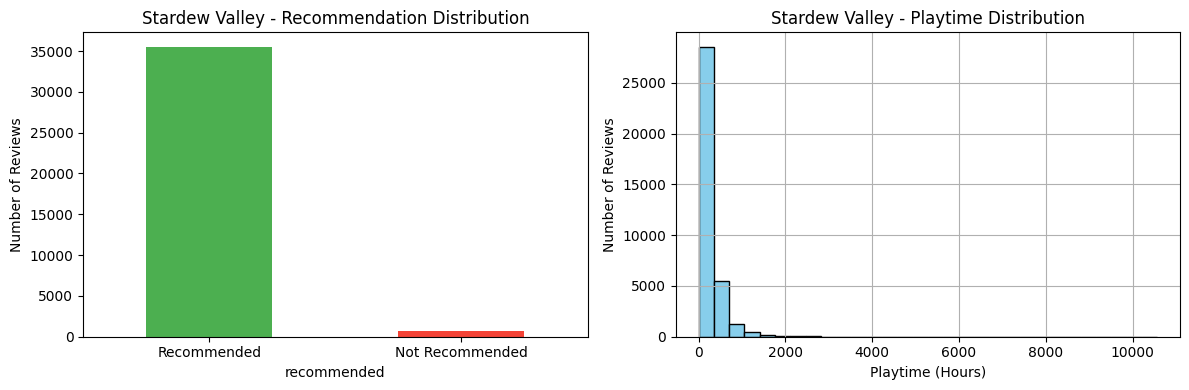

In [11]:
# 시각화
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# 추천/비추천 막대 그래프
df['recommended'].value_counts().plot(
    kind='bar',
    ax=axes[0],
    color=['#4CAF50', '#f44336']
)
axes[0].set_title(f'{MY_GAME_NAME} - Recommendation Distribution')
axes[0].set_xticklabels(['Recommended', 'Not Recommended'], rotation=0)
axes[0].set_ylabel('Number of Reviews')

# 플레이 시간 히스토그램
df['playtime_hours'].hist(
    bins=30,
    ax=axes[1],
    color='skyblue',
    edgecolor='black'
)
axes[1].set_title(f'{MY_GAME_NAME} - Playtime Distribution')
axes[1].set_xlabel('Playtime (Hours)')
axes[1].set_ylabel('Number of Reviews')

plt.tight_layout()
plt.show()

## 7. CSV 파일로 저장하기

수집한 데이터를 파일로 저장합니다.

In [12]:
# 파일명 생성 (게임 이름 + 날짜)
from datetime import datetime

today = datetime.now().strftime('%Y%m%d')
filename = f"{MY_GAME_NAME.replace(' ', '_')}_reviews_{today}.csv"

# CSV 저장 (한글 깨짐 방지)
df.to_csv(filename, index=False, encoding='utf-8-sig')
print(f"저장 완료: {filename}")
print(f"파일 크기: {len(df)}개 리뷰")

저장 완료: Stardew_Valley_reviews_20261122.csv
파일 크기: 36214개 리뷰


## 8. 파일 다운로드하기

Colab에서 내 컴퓨터로 파일을 다운로드합니다.

In [13]:
# (Colab 전용) 파일 다운로드
try:
    from google.colab import files
    files.download(filename)
    print(f"\n'{filename}' 다운로드 시작!")
except:
    print(f"로컬 환경에서 실행 중 - '{filename}'이 현재 디렉토리에 저장됨")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


'Stardew_Valley_reviews_20261122.csv' 다운로드 시작!


---

## 정리

### 오늘 배운 것
1. Steam 스토어에서 게임 ID 찾기
2. `steamreviews`로 리뷰 데이터 수집
3. 딕셔너리 → DataFrame 변환
4. CSV 파일 저장 및 다운로드